# Vision — Anotasi Sendiri untuk Klasifikasi (embedding → klaster → beri nama)
**Kapan dipakai:** ada ribuan gambar **tanpa label** dan kita harus melabeli sendiri.

**Langkah:** gambar → embedding CLIP → KMeans → lihat grid tiap klaster → **beri satu nama per
klaster** di `CLUSTER_NAMES` → periksa gambar paling jauh dari pusat klaster, koreksi manual di
`CORRECTIONS` → cek kualitas label dengan LogReg.

**Urutan kerja:** jalankan sampai sel grid → lihat gambar → isi `CLUSTER_NAMES` → jalankan ulang.

**Data demo:** CIFAR-10 kecil (4.000 gambar). Nama folder kelas **tidak dipakai** sampai sel
kunci jawaban terakhir.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import cross_val_predict
from transformers import CLIPModel, CLIPProcessor

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/classification/cifar10_small/train"
# ↑ GANTI saat lomba
IMAGE_PATTERN = "*.png"     # dicari di semua subfolder. Ganti "*.jpg" bila perlu
CLIP_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/clip_b32"
PRETRAINED = "Z:/GEMASTIK-DATABASE/pretrained"

N_CLUSTERS = 10       # jumlah klaster, boleh lebih banyak dari jumlah kelas
PER_ROW = 10          # jumlah gambar per baris grid
BATCH_SIZE = 128
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

# Nama kelas tiap klaster. Isi SETELAH melihat grid. Dua klaster boleh punya nama sama.
CLUSTER_NAMES = {0: "airplane", 1: "frog", 2: "bird", 3: "automobile", 4: "horse",
                 5: "truck", 6: "deer", 7: "ship", 8: "cat", 9: "dog"}
# Koreksi per gambar setelah memeriksa sampel terjauh, contoh: {"cat/0001.png": "dog"}
CORRECTIONS = {}

## Baca data (hanya daftar gambar, tanpa label)

In [3]:
image_paths = sorted(glob.glob(f"{DATA_FOLDER}/**/{IMAGE_PATTERN}", recursive=True))
print("jumlah gambar:", len(image_paths), "| contoh:", image_paths[0])

jumlah gambar: 4000 | contoh: Z:/GEMASTIK-DATABASE/data_latihan/vision/classification/cifar10_small/train\airplane\0000.png


## Embedding gambar (CLIP ViT-B/32 lokal)
Tiap vektor dibuat panjang 1 supaya jarak KMeans = beda arah (cosine).

In [4]:
clip = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
clip = clip.to(DEVICE)
clip.eval()
processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)


def embed_images(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        images = []
        for path in paths[start:start + BATCH_SIZE]:
            images.append(Image.open(path).convert("RGB"))
        encoded = processor(images=images, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            output = clip.get_image_features(**encoded)
        batches.append(output.pooler_output.cpu().numpy())
    vectors = np.concatenate(batches)
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


embeddings = embed_images(image_paths)
print("ukuran embedding:", embeddings.shape)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

ukuran embedding: (4000, 512)


### Alternatif: embedding ResNet18
Hapus `#` di sel ini dan jalankan setelah sel di atas. Nomor klaster akan berubah, jadi lihat
grid lagi dan isi ulang `CLUSTER_NAMES`.

In [5]:
# from torchvision import models, transforms
# resnet = models.resnet18(weights=None)
# resnet.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
# resnet.fc = torch.nn.Identity()
# resnet = resnet.to(DEVICE)
# resnet.eval()
# prepare = transforms.Compose([transforms.Resize(224), transforms.ToTensor(),
#                               transforms.Normalize([0.485, 0.456, 0.406],
#                                                    [0.229, 0.224, 0.225])])
# batches = []
# for start in range(0, len(image_paths), BATCH_SIZE):
#     tensors = []
#     for path in image_paths[start:start + BATCH_SIZE]:
#         tensors.append(prepare(Image.open(path).convert("RGB")))
#     with torch.no_grad():
#         batches.append(resnet(torch.stack(tensors).to(DEVICE)).cpu().numpy())
# embeddings = np.concatenate(batches)
# embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)

## KMeans dan grid per klaster
Tiap baris grid = satu klaster, urut dari gambar paling dekat pusat (paling khas).

ukuran klaster: [337 583 496 365 345 426 365 386 429 268]


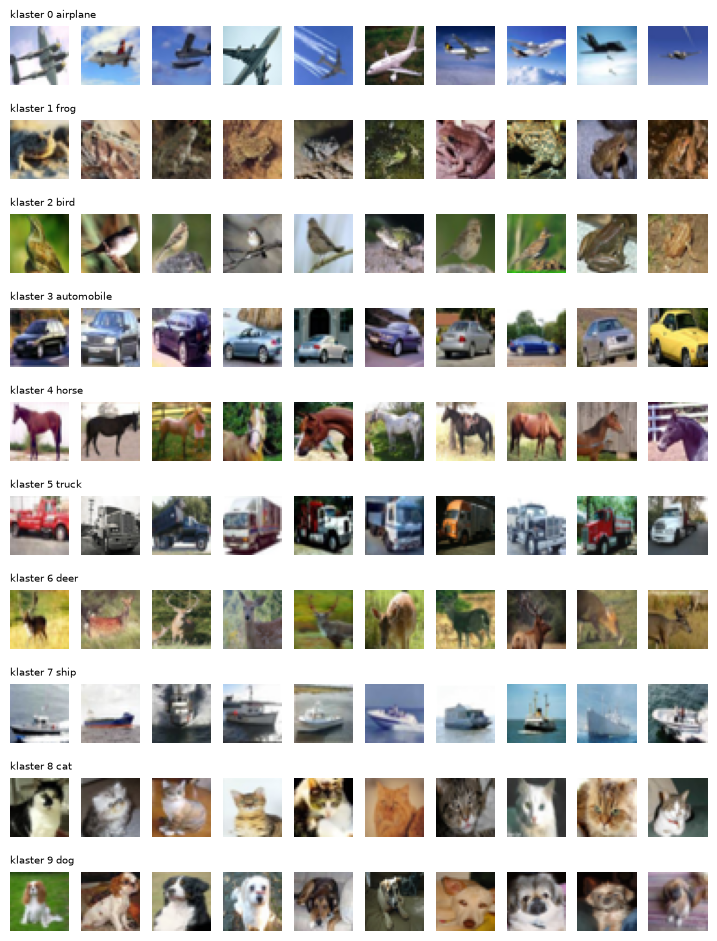

In [6]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
clusters = kmeans.fit_predict(embeddings)
distances = np.linalg.norm(embeddings - kmeans.cluster_centers_[clusters], axis=1)
print("ukuran klaster:", np.bincount(clusters))

sorted_rows = []     # nomor baris gambar tiap klaster, dari paling dekat ke paling jauh
for cluster in range(N_CLUSTERS):
    rows = np.where(clusters == cluster)[0]
    sorted_rows.append(rows[np.argsort(distances[rows])])


def show_grid(rows_per_cluster, file_name):
    fig, axes = plt.subplots(N_CLUSTERS, PER_ROW, figsize=(PER_ROW * 0.9, N_CLUSTERS * 1.2))
    for ax in axes.ravel():
        ax.axis("off")
    for cluster in range(N_CLUSTERS):
        name = CLUSTER_NAMES.get(cluster, "?")
        axes[cluster, 0].set_title(f"klaster {cluster} {name}", loc="left", fontsize=7)
        for column, row in enumerate(rows_per_cluster[cluster][:PER_ROW]):
            axes[cluster, column].imshow(Image.open(image_paths[row]))
    fig.savefig(file_name, dpi=90, bbox_inches="tight")
    plt.show()


show_grid(sorted_rows, "grid_khas.png")

## Beri label dari nama klaster, lalu koreksi manual
Alternatif tanpa klaster (zero-shot CLIP): bandingkan embedding gambar dengan embedding teks
"a photo of a {kelas}" dan ambil kelas dengan cosine tertinggi.

In [7]:
relative_paths = []
labels = []
for path, cluster in zip(image_paths, clusters):
    relative_path = os.path.relpath(path, DATA_FOLDER).replace("\\", "/")
    label = CLUSTER_NAMES.get(cluster, f"klaster_{cluster}")
    if relative_path in CORRECTIONS:
        label = CORRECTIONS[relative_path]
    relative_paths.append(relative_path)
    labels.append(label)

table = pd.DataFrame()
table["path"] = relative_paths
table["cluster"] = clusters
table["distance"] = distances
table["label"] = labels
print(table["label"].value_counts())

label
frog          583
bird          496
cat           429
truck         426
ship          386
automobile    365
deer          365
horse         345
airplane      337
dog           268
Name: count, dtype: int64


## Periksa sampel paling jauh dari pusat klaster (paling mungkin salah klaster)

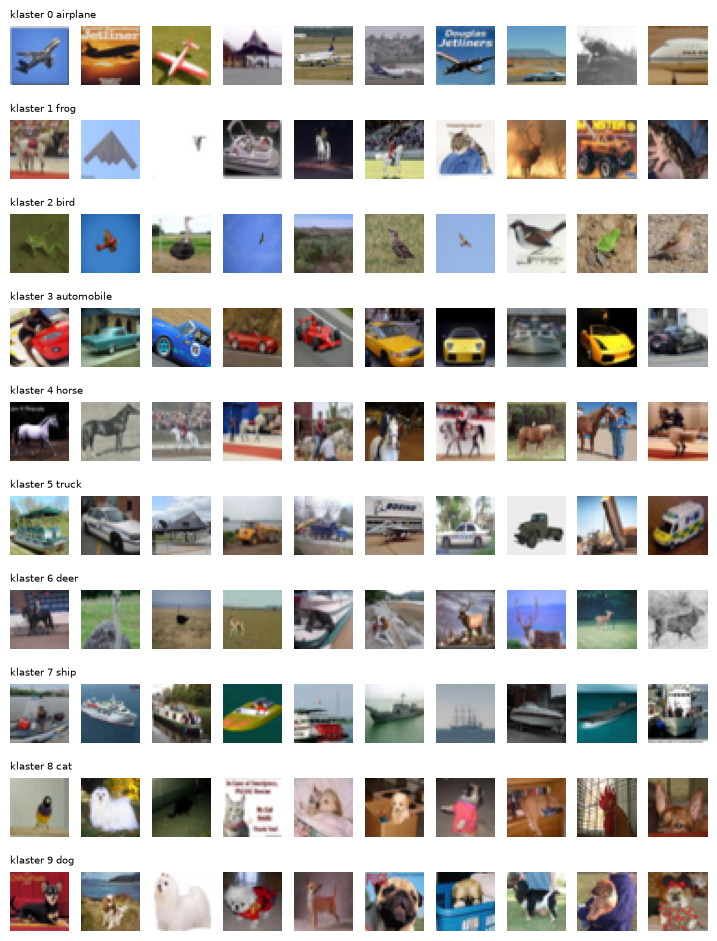

,path,cluster,distance,label
3135,horse/0335.png,4,0.669302,horse
2654,frog/0254.png,2,0.647682,bird
213,airplane/0213.png,0,0.639180,airplane
78,airplane/0078.png,0,0.637142,airplane
2831,horse/0031.png,1,0.630646,frog
765,automobile/0365.png,3,0.619575,automobile
95,airplane/0095.png,0,0.614493,airplane
3593,ship/0393.png,5,0.613713,truck
219,airplane/0219.png,0,0.607725,airplane
278,airplane/0278.png,0,0.607685,airplane


In [8]:
farthest_rows = []
for rows in sorted_rows:
    farthest_rows.append(rows[::-1])
show_grid(farthest_rows, "grid_terjauh.png")
table.sort_values("distance", ascending=False).head(10)

## Simpan CSV label

In [9]:
table[["path", "label"]].to_csv("label_awal.csv", index=False)
print("tersimpan: label_awal.csv")

tersimpan: label_awal.csv


## Cek kualitas label: LogReg di embedding (cross-validation)
Gambar yang label kita kurang diyakini LogReg = kandidat label salah, periksa manual.

In [10]:
checker = LogisticRegression(max_iter=1000)
proba = cross_val_predict(checker, embeddings, table["label"], cv=5, method="predict_proba")
class_names = list(np.sort(table["label"].unique()))
checker_labels = []
own_label_confidence = []
for row, label in enumerate(table["label"]):
    checker_labels.append(class_names[proba[row].argmax()])
    own_label_confidence.append(proba[row, class_names.index(label)])
table["confidence"] = own_label_confidence

score = f1_score(table["label"], checker_labels, average="macro")
print("F1 macro (label kita vs LogReg):", round(score, 3))
table.sort_values("confidence").head(10)

F1 macro (label kita vs LogReg): 0.957


,path,cluster,distance,label,confidence
2364,dog/0364.png,6,0.521943,deer,0.126462
377,airplane/0377.png,1,0.489863,frog,0.146969
1364,cat/0164.png,1,0.461888,frog,0.169290
50,airplane/0050.png,1,0.393194,frog,0.170210
841,bird/0041.png,6,0.480892,deer,0.172096
3012,horse/0212.png,8,0.507943,cat,0.176806
222,airplane/0222.png,1,0.438846,frog,0.181604
3529,ship/0329.png,6,0.529611,deer,0.181951
382,airplane/0382.png,5,0.501486,truck,0.186830
2997,horse/0197.png,6,0.606624,deer,0.189354


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Kelas asli di data demo = nama folder gambar.

In [11]:
true_classes = []
for path in image_paths:
    true_classes.append(os.path.basename(os.path.dirname(path)))
print("akurasi label kita vs kelas asli:", round(accuracy_score(true_classes, table["label"]), 3))
print(pd.crosstab(pd.Series(true_classes, name="asli"), table["label"]))

akurasi label kita vs kelas asli: 0.776
label       airplane  automobile  bird  cat  deer  dog  frog  horse  ship  \
asli                                                                        
airplane         329           0     3    0     0    0    56      0     4   
automobile         1         360     0    0     0    0     9      0     0   
bird               1           0   278   18    38    1    61      1     1   
cat                0           0    14  295     4    6    81      0     0   
deer               0           0    11    4   292    0    85      8     0   
dog                0           0     0   92     6  260    38      4     0   
frog               0           0   189   11     7    0   192      1     0   
horse              0           0     1    9    17    1    41    331     0   
ship               5           3     0    0     1    0     9      0   381   
truck              1           2     0    0     0    0    11      0     0   

label       truck  
asli           